In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load crop_yield.csv into a DataFrame named crop_df
crop_df = pd.read_csv("C:/Users/Hp/Downloads/crop_yield.csv")

# 2. Display the first 10 rows
print(crop_df.head(10))

# 3. Check missing values in each column
print(crop_df.isnull().sum())

# 4. View data types of all columns
print(crop_df.dtypes)

# 5. Statistical summary of numeric columns
print(crop_df.describe())

# 6. Statistical summary of object/text columns
print(crop_df.describe(include='object'))

  FARM_ID CROP_TYPE  YIELD_KG  AREA_ACRES HARVEST_DATE    DISTRICT SEASON  \
0    F001     Wheat    1500.0         4.0   01/01/2023     Sialkot   Rabi   
1    F002     Wheat    1500.0         5.0   02/01/2023      Multan   Rabi   
2    F003     Wheat    2500.0         5.0   03/01/2023  Faisalabad   Rabi   
3    F004     Wheat    1500.0         NaN   04/01/2023      Multan   Rabi   
4    F005      Rice    1500.0         4.0   05/01/2023  Faisalabad   Rabi   
5    F006      Rice    2000.0         6.0   06/01/2023  Faisalabad   Rabi   
6    F007     Maize    1500.0         6.0   07/01/2023  Faisalabad   Rabi   
7    F008     Wheat    1500.0         5.0   08/01/2023      Lahore   Rabi   
8    F009     Wheat    2000.0         5.0   09/01/2023  Faisalabad   Rabi   
9    F010     Wheat    1500.0         3.0   10/01/2023  Faisalabad   Rabi   

  FERTILIZER_USED  YIELD_VALUE  
0             Yes        30000  
1              No        30000  
2             Yes        50000  
3             Yes   

C:\Users\Hp\AppData\Local\Temp\ipykernel_23672\2861138538.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(crop_df.describe(include='object'))


In [2]:
# 7. Remove rows where YIELD_KG is missing
crop_df = crop_df.dropna(subset=['YIELD_KG']).copy()

# 8. Fill missing AREA_ACRES with column mean
crop_df['AREA_ACRES'] = crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())

# 9. Replace missing DISTRICT with 'Unknown'
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')

# 10. Replace missing FERTILIZER_USED with 'No'
crop_df['FERTILIZER_USED'] = crop_df['FERTILIZER_USED'].fillna('No')

# 11. Replace missing YIELD_VALUE with column mean
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())

# 12. Convert HARVEST_DATE to datetime format (%d/%m/%Y)
crop_df['HARVEST_DATE'] = pd.to_datetime(
    crop_df['HARVEST_DATE'], format='%d/%m/%Y', errors='coerce'
)

# 13. Remove 'F' from FARM_ID and convert to integer
crop_df['FARM_ID'] = (
    crop_df['FARM_ID'].astype(str).str.replace('F', '', regex=False).astype(int)
)

# 14. Re-check missing values
print(crop_df.isnull().sum())

# 15. Re-check data types
print(crop_df.dtypes)

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64
FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object


            YIELD_KG
CROP_TYPE           
Maize      1112500.0
Rice       1638000.0
Sugarcane   592000.0
Wheat      2035500.0


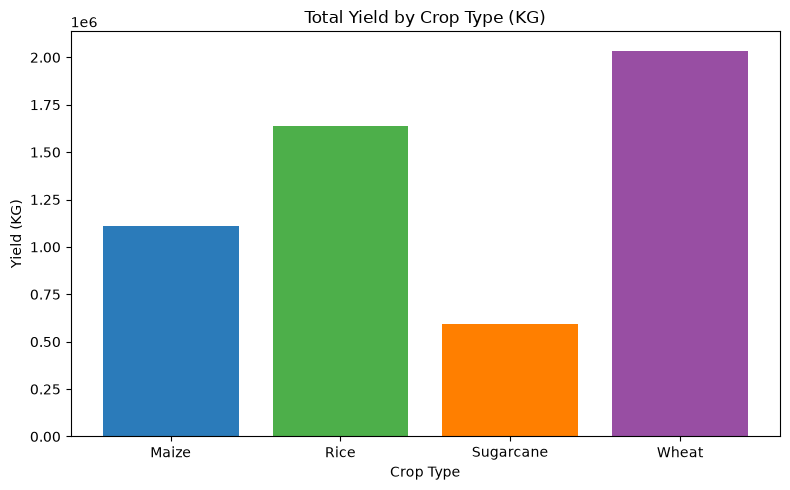

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
2023-01-06      2000.0
2023-01-07      1500.0
2023-01-08      1500.0
2023-01-09      2000.0
2023-01-10      1500.0


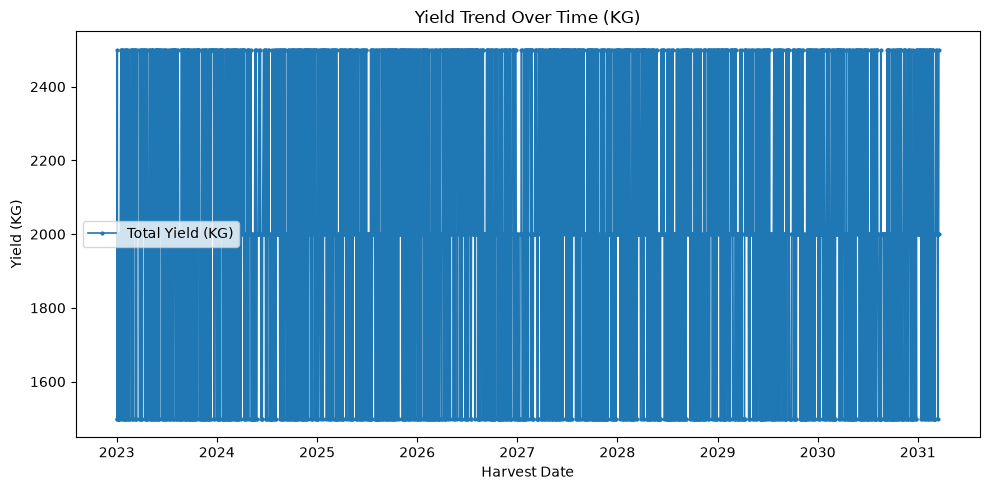

In [3]:
# 16. Total yield (KG) by crop type
crop_yield_total = crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})
print(crop_yield_total)

# 17. Bar chart of Total Yield by Crop Type (KG)
plt.figure(figsize=(8, 5))
plt.bar(
    crop_yield_total.index,
    crop_yield_total['YIELD_KG'],
    color=['#2b7bba', '#4daf4a', '#ff7f00', '#984ea3'],
)
plt.title('Total Yield by Crop Type (KG)')
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')
plt.tight_layout()
plt.show()

# 18. Pivot table summarizing total yield by harvest date
pivot_yield = crop_df.pivot_table(
    values='YIELD_KG', index='HARVEST_DATE', aggfunc='sum'
)
print(pivot_yield.head(10))

# 19. Line chart of yield trend over time saved as 'crop_yield_trend.png'
plt.figure(figsize=(10, 5))
plt.plot(
    pivot_yield.index,
    pivot_yield['YIELD_KG'],
    marker='o',
    markersize=2,
    linewidth=1.2,
    label='Total Yield (KG)',
)
plt.title('Yield Trend Over Time (KG)')
plt.xlabel('Harvest Date')
plt.ylabel('Yield (KG)')
plt.legend()
plt.tight_layout()
plt.savefig('crop_yield_trend.png', dpi=150)
plt.show()